# 1. Persiapan Lingkungan dan Import Pustaka
Pipeline V2 dengan arsitektur MobileNetV2 yang dioptimasi secara ekstensif untuk dataset berukuran kecil (penambahan Dropout, Dense Layer, standar pra-pemrosesan Keras, dan implementasi Callbacks/EarlyStopping).

In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import splitfolders
import albumentations as A
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Konfigurasi GPU (Opsional)
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU Siap dengan memory growth aktif.")
    except RuntimeError as e:
        print(e)
else:
    print("Menggunakan Komputasi CPU.")


Menggunakan Komputasi CPU.


# 2. Partisi Dataset

In [ ]:
input_dir = 'dataset'
output_dir_v2 = 'dataset_split_v2'

# Memisahkan folder utama menjadi Train (70%), Val (15%), Test (15%)
if not os.path.exists(output_dir_v2):
    if os.path.exists(input_dir) and len(os.listdir(input_dir)) > 0:
        print("Mengeksekusi pemisahan dataset...")
        splitfolders.ratio(input_dir, output=output_dir_v2, seed=42, ratio=(0.7, 0.15, 0.15))
        print("Pemisahan selesai.")
    else:
        print("ERROR: Folder 'dataset' kosong atau tidak ada.")
else:
    print("Folder 'dataset_split' sudah ada. Lanjut ke proses berikutnya.")


Folder 'dataset_split' sudah ada. Lanjut ke proses berikutnya.


# 3. Pra-pemrosesan Data (ImageDataGenerator + Albumentations)
Kita mengintegrasikan `Albumentations` langsung ke dalam parameter `preprocessing_function` dari Keras. Hal ini menjamin efisiensi memori, ditambah pemanggilan fungsi wajib `preprocess_input` khusus dari MobileNetV2 untuk memetakan piksel ke rentang `[-1, 1]`.

In [ ]:
# Definisi Augmentasi Fisik & Warna
transform = A.Compose([
    A.Rotate(limit=30, p=0.5),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.Affine(scale=(0.8, 1.2), p=0.5), # Zoom
    A.GaussNoise(var_limit=(10.0, 50.0), p=0.5),
])

# Fungsi Wrapper untuk ImageDataGenerator (Data Latih)
def aug_fn(image):
    # Keras memberikan gambar dalam bentuk numpy array float32 [0, 255]
    data = {"image": image.astype(np.uint8)}
    aug_data = transform(**data)
    aug_img = aug_data["image"].astype(np.float32)
    # Sangat Krusial: Transformasi ke skala [-1, 1] standar MobileNetV2
    return preprocess_input(aug_img) 

# Fungsi Wrapper tanpa augmentasi (Data Validasi & Uji)
def no_aug_fn(image):
    return preprocess_input(image.astype(np.float32))

BATCH_SIZE = 32
IMG_SIZE = (224, 224)

train_datagen = ImageDataGenerator(preprocessing_function=aug_fn)
val_test_datagen = ImageDataGenerator(preprocessing_function=no_aug_fn)

train_gen = train_datagen.flow_from_directory(
    os.path.join(output_dir_v2, 'train'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_gen = val_test_datagen.flow_from_directory(
    os.path.join(output_dir_v2, 'val'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_gen = val_test_datagen.flow_from_directory(
    os.path.join(output_dir_v2, 'test'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# Mengambil list kelas
classes = list(train_gen.class_indices.keys())
print("\nKelas Terdeteksi:", classes)


C:\Users\peno\AppData\Local\Temp\ipykernel_1576\3115389357.py:7: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0), p=0.5),


Found 597 images belonging to 4 classes.
Found 127 images belonging to 4 classes.
Found 133 images belonging to 4 classes.

Kelas Terdeteksi: ['Lewat Matang', 'Matang', 'Mengkal', 'Mentah']


# 4. Arsitektur Model Baru & Callbacks Pelatihan
Penambahan `Dense(256)` dan `Dropout(0.5)` mengatasi ketidakmampuan model dasar membaca fitur spesifik sawit. Ditambah penerapan `EarlyStopping` dan `ModelCheckpoint` agar hasil panen terbaik di-save otomatis tanpa khawatir rusak di epoch terakhir.

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

if classes:
    # 1. Base Model (Frozen)
    base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False

    # 2. Modifikasi Top Layers (Telah Diperkuat)
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(256, activation='relu')(x) # Hidden layer baru untuk kapabilitas berpikir
    x = Dropout(0.5)(x)                  # Mencegah overfitting secara ekstrim
    predictions = Dense(len(classes), activation='softmax')(x)
    
    model = Model(inputs=base_model.input, outputs=predictions)

    # 3. Kompilasi Tahap 1 (Learning rate 1e-3 agar top layer cepat belajar)
    model.compile(optimizer=Adam(learning_rate=1e-3), 
                  loss='categorical_crossentropy', 
                  metrics=['accuracy'])

    # 4. Kalkulasi Class Weights Otomatis untuk Keadilan Pembelajaran
    train_labels = train_gen.classes
    class_weights_arr = compute_class_weight(class_weight='balanced', classes=np.unique(train_labels), y=train_labels)
    class_weight_dict = {i: weight for i, weight in enumerate(class_weights_arr)}
    print("Class Weights:", class_weight_dict)

    # 5. Persiapan Callbacks Keamanan
    checkpoint = ModelCheckpoint('best_model.keras', monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)
    early_stop = EarlyStopping(monitor='val_accuracy', patience=7, restore_best_weights=True, verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
    callbacks_list = [checkpoint, early_stop, reduce_lr]

    print("\n--- Mulai Tahap 1 (Feature Extraction / Frozen Base) ---")
    # Pelatihan Berjalan
    history_phase1 = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=20,
        class_weight=class_weight_dict,
        callbacks=callbacks_list
    )
else:
    print("Dataset kosong.")


Class Weights: {0: np.float64(1.9134615384615385), 1: np.float64(0.9270186335403726), 2: np.float64(0.6405579399141631), 3: np.float64(1.194)}

--- Mulai Tahap 1 (Feature Extraction / Frozen Base) ---
Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.2439 - loss: 2.0083
Epoch 1: val_accuracy improved from None to 0.45669, saving model to best_model.keras
19/19 ━━━━━━━━━━━━━━━━━━━━ 223s 8s/step - accuracy: 0.3082 - loss: 1.7114 - val_accuracy: 0.4567 - val_loss: 1.1921 - learning_rate: 0.0010
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4222 - loss: 1.2548
Epoch 2: val_accuracy improved from 0.45669 to 0.55118, saving model to best_model.keras
19/19 ━━━━━━━━━━━━━━━━━━━━ 64s 3s/step - accuracy: 0.4355 - loss: 1.2286 - val_accuracy: 0.5512 - val_loss: 0.9827 - learning_rate: 0.0010
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.4432 - loss: 1.1175
Epoch 3: val_accuracy improved from 0.55118 to 0.62205, saving model to best_model.keras
19/19 ━

# 5. Fine Tuning Lanjutan (Tahap 2)

In [ ]:
if classes:
    # Buka seluruh gembok layer
    base_model.trainable = True
    # Kunci kembali layer-layer dasar (kecuali 30 layer teratas)
    for layer in base_model.layers[:-30]:
        layer.trainable = False

    # Kompilasi Ulang dengan LR super lambat (1e-5)
    model.compile(optimizer=Adam(learning_rate=1e-5), 
                  loss='categorical_crossentropy', 
                  metrics=['accuracy'])

    print("\n--- Mulai Tahap 2 (Fine-Tuning 30 Layers Atas) ---")
    # Pelatihan Tahap 2 Berjalan
    history_phase2 = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=30,
        class_weight=class_weight_dict,
        callbacks=callbacks_list
    )
else:
    pass



--- Mulai Tahap 2 (Fine-Tuning 30 Layers Atas) ---
Epoch 1/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3750 - loss: 1.4954
Epoch 1: val_accuracy did not improve from 0.66929
19/19 ━━━━━━━━━━━━━━━━━━━━ 71s 3s/step - accuracy: 0.4037 - loss: 1.4150 - val_accuracy: 0.6614 - val_loss: 0.7879 - learning_rate: 1.0000e-05
Epoch 2/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4777 - loss: 1.2538
Epoch 2: val_accuracy did not improve from 0.66929
19/19 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step - accuracy: 0.4925 - loss: 1.2612 - val_accuracy: 0.6535 - val_loss: 0.7896 - learning_rate: 1.0000e-05
Epoch 3/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4914 - loss: 1.0569
Epoch 3: val_accuracy did not improve from 0.66929

Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
19/19 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.4841 - loss: 1.0870 - val_accuracy: 0.6457 - val_loss: 0.7924 - learning_rate: 1.0000e-05
Epoch 4/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s

# 6. Kuantisasi ke Format Android (TensorFlow Lite)

In [ ]:
if classes and os.path.exists('best_model.keras'):
    print("Memuat bobot terbaik dan Melakukan Kuantisasi (Float16)...")
    # Karena EarlyStopping me-restore best weights, 'model' di memori adalah yang terbaik.
    # Anda juga bisa secara eksplisit me-load best_model.keras
    # model.load_weights('best_model.keras')
    
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.target_spec.supported_types = [tf.float16]

    # Menjalankan Kuantisasi
    tflite_quant_model = converter.convert()
    tflite_filepath = "mobilenetv2_sawit_fp16.tflite"
    with open(tflite_filepath, "wb") as f:
        f.write(tflite_quant_model)
    print(f"Model TFLite tersimpan sebagai {tflite_filepath}")
else:
    print("Menunggu hasil pelatihan untuk dikuantisasi.")


Memuat bobot terbaik dan Melakukan Kuantisasi (Float16)...
INFO:tensorflow:Assets written to: C:\Users\peno\AppData\Local\Temp\tmp9x2pan7x\assets


INFO:tensorflow:Assets written to: C:\Users\peno\AppData\Local\Temp\tmp9x2pan7x\assets


Saved artifact at 'C:\Users\peno\AppData\Local\Temp\tmp9x2pan7x'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_160')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  2292874388304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2292874387248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2292874389888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2292874385488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2292874387776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2292874392880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2292874658736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2292874395344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2292874394992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2292874658384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  22

# 7. Evaluasi Akhir (Data Uji 15%)

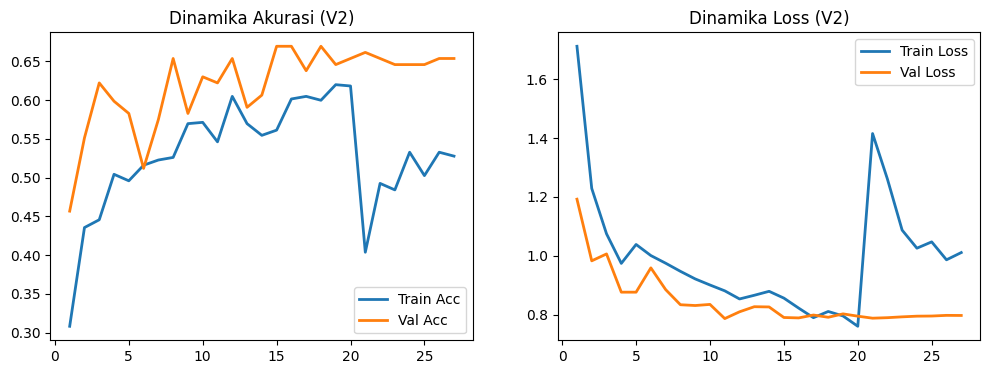


--- Mengukur Metrik di Dataset Uji ---
5/5 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step


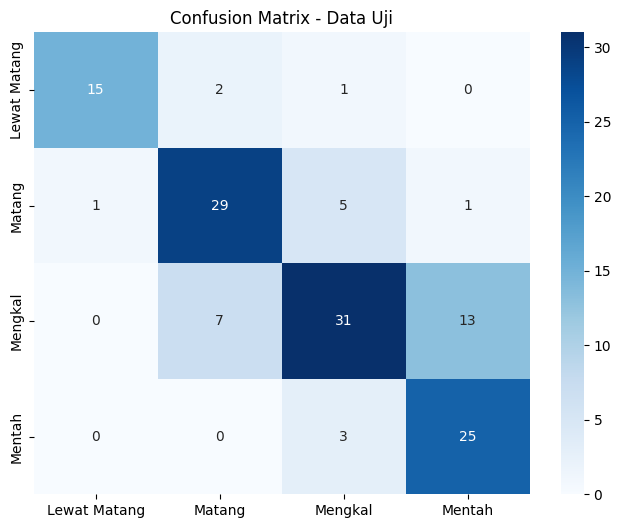


LAPORAN AKHIR V2 (CLASSIFICATION REPORT)
              precision    recall  f1-score   support

Lewat Matang       0.94      0.83      0.88        18
      Matang       0.76      0.81      0.78        36
     Mengkal       0.78      0.61      0.68        51
      Mentah       0.64      0.89      0.75        28

    accuracy                           0.75       133
   macro avg       0.78      0.78      0.77       133
weighted avg       0.77      0.75      0.75       133



In [ ]:
if 'history_phase1' in locals() and 'history_phase2' in locals():
    def plot_curves(h1, h2):
        acc = h1.history['accuracy'] + h2.history['accuracy']
        val_acc = h1.history['val_accuracy'] + h2.history['val_accuracy']
        loss = h1.history['loss'] + h2.history['loss']
        val_loss = h1.history['val_loss'] + h2.history['val_loss']
        epochs_range = range(1, len(acc) + 1)
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 2, 1)
        plt.plot(epochs_range, acc, label='Train Acc', linewidth=2)
        plt.plot(epochs_range, val_acc, label='Val Acc', linewidth=2)
        plt.legend(loc='lower right')
        plt.title('Dinamika Akurasi (V2)')
        plt.subplot(1, 2, 2)
        plt.plot(epochs_range, loss, label='Train Loss', linewidth=2)
        plt.plot(epochs_range, val_loss, label='Val Loss', linewidth=2)
        plt.legend(loc='upper right')
        plt.title('Dinamika Loss (V2)')
        plt.show()

    plot_curves(history_phase1, history_phase2)

if classes:
    print("\n--- Mengukur Metrik di Dataset Uji ---")
    test_gen.reset() # Mereset urutan pointer sebelum memprediksi
    y_pred_probs = model.predict(test_gen)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = test_gen.classes

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title('Confusion Matrix - Data Uji')
    plt.show()

    print("\n=======================================================")
    print("LAPORAN AKHIR V2 (CLASSIFICATION REPORT)")
    print("=======================================================")
    print(classification_report(y_true, y_pred, target_names=classes))
